# Chuẩn bị dữ liệu hỏi đáp pháp luật giao thông

Bộ dữ liệu tiếng Việt chốt theo ngày **13/11/2026**, gồm câu hỏi tra cứu theo điều khoản và câu hỏi diễn đạt tự nhiên. Mỗi đáp án giữ nội dung trích từ văn bản chính thức, kèm số hiệu và vị trí trong PDF. Mở notebook bằng kernel Python của dự án sau khi cài `requirements.txt`.

In [1]:
from collections import Counter
from pathlib import Path
import json
import os
import subprocess
import sys
import tomllib

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / "configs/dataset.toml").is_file())
DATA = ROOT / "data/processed"
config = tomllib.loads((ROOT / "configs/dataset.toml").read_text(encoding="utf-8"))
model = tomllib.loads((ROOT / "configs/environment.toml").read_text(encoding="utf-8"))["models"]["primary"]

def read_rows(name):
    return [json.loads(line) for line in (DATA / f"{name}.jsonl").read_text(encoding="utf-8").splitlines()]

## Nguồn và hiệu lực

Kiểm tra hiệu lực ở cấp điều, khoản bằng mốc mặc định, chú thích sửa đổi và ngoại lệ đã đối chiếu. Báo cáo đi kèm ghi rõ văn bản được rà soát và các phần loại khỏi tập dữ liệu.

In [2]:
from IPython.display import Markdown, display

sources = ["| Văn bản | Phiên bản dùng để trích |", "|---|---|"]
for source in config["sources"]:
    sources.append(f"| {source['document_id']} | [{source['edition']}]({source['source_url']}) |")
display(Markdown("\n".join(sources)))

| Văn bản | Phiên bản dùng để trích |
|---|---|
| 36/2024/QH15 | [55/VBHN-VPQH](https://vanban.chinhphu.vn/?docid=217295&pageid=27160) |
| 35/2024/QH15 | [49/VBHN-VPQH](https://vanban.chinhphu.vn/?docid=217234&pageid=27160) |
| 165/2024/NĐ-CP | [65/2026/VBHN-NĐ-BXD](https://vanban.chinhphu.vn/?docid=219312&pageid=27160) |
| 38/2024/TT-BGTVT | [38/2024/TT-BGTVT](https://vanban.chinhphu.vn/?docid=211873&pageid=27160) |

## Tiền xử lý và kiểm chứng

Script xác minh SHA-256 của PDF, tách điều khoản, chuẩn hóa Unicode NFC và kiểm tra các trường bắt buộc. Đặt `REBUILD = True` để dựng lại bốn tệp chính và tập ngoài phạm vi. Khi tệp đã tồn tại, notebook xác minh lại nội dung đã lưu. Lần đầu cần Internet để tải nguồn hoặc tokenizer chưa có trong cache.

In [3]:
REBUILD = False
env = os.environ.copy()
model_dir = "models--" + model["id"].replace("/", "--")
cached_tokenizer = ROOT / "artifacts/hf-cache" / model_dir / "snapshots" / model["revision"] / "tokenizer.json"
command = [sys.executable, "-X", "utf8", str(ROOT / "scripts/prepare_legal_dataset.py"), "--download"]
if cached_tokenizer.is_file():
    env["HF_HUB_CACHE"] = str(ROOT / "artifacts/hf-cache")
    command.append("--offline")
if not REBUILD and (DATA / "statistics.json").is_file():
    command.append("--verify-only")

run = subprocess.run(command, cwd=ROOT, env=env, capture_output=True, text=True, encoding="utf-8")
if run.returncode:
    raise RuntimeError(run.stderr)
summary = json.loads((DATA / "statistics.json").read_text(encoding="utf-8"))
master = read_rows("legal_qa_master")
splits = {name: read_rows(name) for name in ("train", "validation", "test")}
print(f"Đã kiểm tra {summary['total']} mẫu với tokenizer {model['id']}.")

Đã kiểm tra 500 mẫu với tokenizer Qwen/Qwen2.5-3B-Instruct.


## Thống kê và phân phối

Độ dài câu hỏi và đáp án đếm theo đơn vị phân cách bằng khoảng trắng. Độ dài chuỗi dùng token Qwen sau khi áp dụng chat template chính thức.

In [4]:
rows = ["| Split | Số mẫu | Nhóm | Câu hỏi viết riêng |", "|---|---:|---:|---:|"]
for name, size in summary["splits"].items():
    authored = summary["question_types"][name].get("authored", 0)
    rows.append(f"| {name} | {size} | {summary['groups'][name]} | {authored} |")
display(Markdown("\n".join(rows)))
print("Trạng thái kiểm chứng", summary["verification_status"])
print("Số mẫu theo văn bản", summary["sources"])
print("Tập ngoài phạm vi", summary["out_of_scope_test"])
display(summary["lengths"])

| Split | Số mẫu | Nhóm | Câu hỏi viết riêng |
|---|---:|---:|---:|
| train | 400 | 181 | 59 |
| validation | 50 | 26 | 9 |
| test | 50 | 23 | 10 |

Trạng thái kiểm chứng {'verified': 500, 'unverified': 0}
Số mẫu theo văn bản {'36/2024/QH15': 245, '35/2024/QH15': 145, '165/2024/NĐ-CP': 100, '38/2024/TT-BGTVT': 10}
Tập ngoài phạm vi 12


{'question_words': {'min': 7, 'median': 28.0, 'max': 119},
 'answer_words': {'min': 21, 'median': 76.0, 'max': 565},
 'sequence_tokens': {'min': 138, 'median': 237.0, 'max': 807},
 'assistant_tokens': {'min': 40, 'median': 107.0, 'max': 684}}

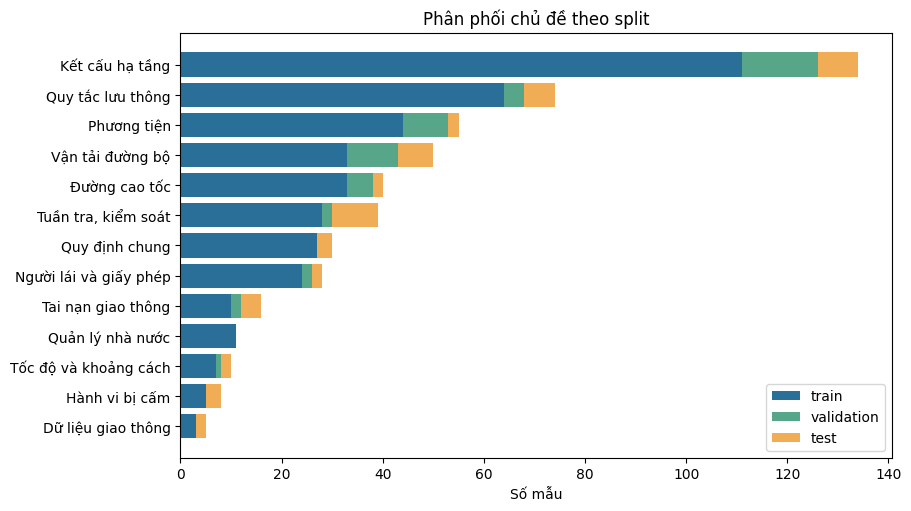

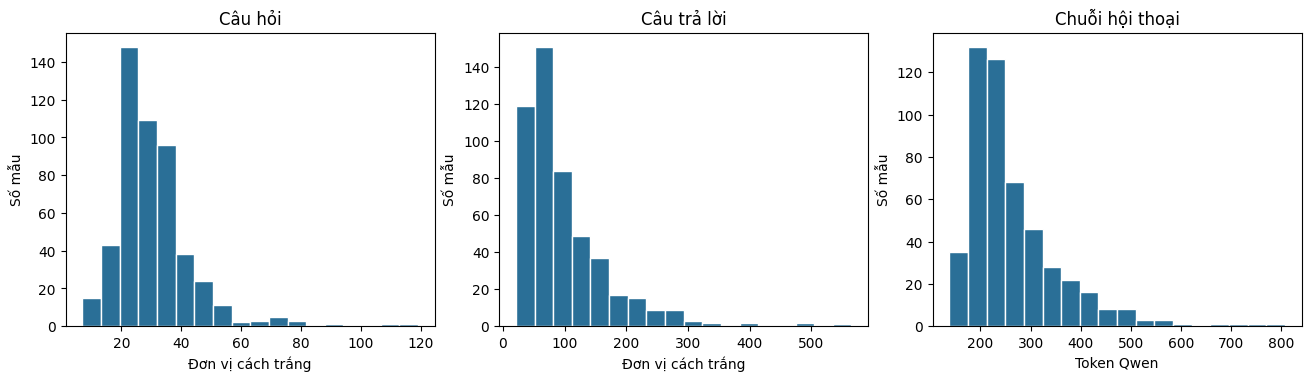

In [5]:
import matplotlib.pyplot as plt

topic_labels = {
    "quy_dinh_chung": "Quy định chung",
    "hanh_vi_bi_cam": "Hành vi bị cấm",
    "quy_tac_luu_thong": "Quy tắc lưu thông",
    "phuong_tien": "Phương tiện",
    "nguoi_lai_va_giay_phep": "Người lái và giấy phép",
    "tuan_tra_kiem_soat": "Tuần tra, kiểm soát",
    "tai_nan_giao_thong": "Tai nạn giao thông",
    "quan_ly_nha_nuoc": "Quản lý nhà nước",
    "ket_cau_ha_tang": "Kết cấu hạ tầng",
    "duong_cao_toc": "Đường cao tốc",
    "van_tai_duong_bo": "Vận tải đường bộ",
    "du_lieu_giao_thong": "Dữ liệu giao thông",
    "toc_do_va_khoang_cach": "Tốc độ và khoảng cách",
}
topics = sorted(summary["topics"], key=summary["topics"].get)
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
bottom = [0] * len(topics)
for split, color in zip(splits, ("#2A6F97", "#58A68A", "#F1AD55")):
    values = [summary["topics_by_split"][split].get(topic, 0) for topic in topics]
    ax.barh([topic_labels[topic] for topic in topics], values, left=bottom, label=split, color=color)
    bottom = [a + b for a, b in zip(bottom, values)]
ax.set(title="Phân phối chủ đề theo split", xlabel="Số mẫu")
ax.legend()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.7), layout="constrained")
for ax, (field, title, unit) in zip(axes, (
    ("question_words", "Câu hỏi", "Đơn vị cách trắng"),
    ("answer_words", "Câu trả lời", "Đơn vị cách trắng"),
    ("sequence_tokens", "Chuỗi hội thoại", "Token Qwen"),
)):
    ax.hist([row[field] for row in master], bins=18, color="#2A6F97", edgecolor="white")
    ax.set(title=title, xlabel=unit, ylabel="Số mẫu")
plt.show()

## Ví dụ từ tập train

Ví dụ lấy từ các mẫu trong tập train. Mỗi trích đoạn được liên kết tới trang đầu của căn cứ trong PDF.

In [6]:
shown = set()
for row in master:
    if row["split"] != "train" or row["topic"] in shown or row["question_type"] != "authored":
        continue
    shown.add(row["topic"])
    display(Markdown(
        f"**{row['question']}**\n\n{row['answer']}\n\n"
        f"[Nguồn, trang {row['pdf_pages'][0]}]({row['source_pdf_url']})"
    ))
    if len(shown) == 3:
        break

**Uống rượu bia rồi lái xe khi hơi thở vẫn còn nồng độ cồn có thuộc hành vi bị cấm không?**

Theo khoản 2 Điều 9 văn bản số 36/2024/QH15, quy định như sau.

Điều khiển phương tiện tham gia giao thông đường bộ mà trong máu hoặc hơi thở có nồng độ cồn.

[Nguồn, trang 7](https://datafiles.chinhphu.vn/cpp/files/vbpq/2026/3/55-vbhn-vpqh.pdf#page=7)

**Khi lưu thông trên đường bộ, người tham gia giao thông phải đi về phía nào và tuân thủ những quy tắc chung nào?**

Theo khoản 1 Điều 10 văn bản số 36/2024/QH15, quy định như sau.

Người tham gia giao thông đường bộ phải đi bên phải theo chiều đi của mình, đi đúng làn đường, phần đường quy định, chấp hành báo hiệu đường bộ và các quy tắc giao thông đường bộ khác.

[Nguồn, trang 10](https://datafiles.chinhphu.vn/cpp/files/vbpq/2026/3/55-vbhn-vpqh.pdf#page=10)

**Người khuyết tật lái mô tô ba bánh chuyên dùng hoặc ô tô số tự động có kết cấu phù hợp được cấp bằng hạng nào?**

Theo khoản 2 Điều 57 văn bản số 36/2024/QH15, quy định như sau.

Người khuyết tật điều khiển xe mô tô ba bánh dùng cho người khuyết tật được cấp giấy phép lái xe hạng A1. Người khuyết tật điều khiển xe ô tô số tự động có kết cấu phù hợp với tình trạng khuyết tật thì được cấp giấy phép lái xe hạng B.

[Nguồn, trang 46](https://datafiles.chinhphu.vn/cpp/files/vbpq/2026/3/55-vbhn-vpqh.pdf#page=46)

## Kiểm tra split và phần tính loss

Group split dùng seed 42. Nhóm dựa trên văn bản và điều, gộp thêm các quy định liên quan đã chỉ định và các đoạn gần trùng. Tệp huấn luyện giữ `prompt`, `completion`, `input_ids` và `completion_mask`. Với TRL 0.22.2, truyền trực tiếp tập JSONL cho SFTTrainer và đặt `completion_only_loss=True` cùng `assistant_only_loss=False`. Mask đã tính sau khi áp dụng chat template Qwen, gồm nội dung assistant và token kết thúc lượt.

In [7]:
from itertools import combinations

ids = {name: {row["id"] for row in rows} for name, rows in splits.items()}
groups = {name: {row["group_id"] for row in master if row["split"] == name} for name in splits}
for left, right in combinations(splits, 2):
    assert not (ids[left] & ids[right])
    assert not (groups[left] & groups[right])
assert set.union(*ids.values()) == {row["id"] for row in master}
assert summary["cross_split_near_duplicate_overlap"] == 0
assert summary["trl_mask_checked"] == len(master)
print("Các split rời nhau theo ID và nhóm. TRL đã kiểm tra mask trên toàn bộ mẫu.")

Các split rời nhau theo ID và nhóm. TRL đã kiểm tra mask trên toàn bộ mẫu.


## Kết luận

Tập dữ liệu có căn cứ truy vết được và có thể tái lập cùng seed, bản PDF và revision tokenizer. Câu hỏi tra cứu nêu rõ căn cứ nên kết quả trên tập này phản ánh năng lực trả lời theo điều khoản. Khi đánh giá câu hỏi người dùng thực tế, cần báo riêng kết quả trên câu hỏi viết riêng và bổ sung tập test tình huống được rà soát độc lập. Tập ngoài phạm vi đánh giá khả năng nhận diện giới hạn chủ đề.